<a href="https://colab.research.google.com/github/jhovasnh06-beep/Metodos-Numericos-1/blob/main/DiferenciasDivididas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fórmula de las Diferencias Divididas de Newton

### Formulación del método
Si tenemos un polinomio $P_n(x)$ que pasa por los $n+1$ nodos $x_0, x_1, \dots, x_n$, podemos reescribirlo en la forma de Newton como:

$$P_n(x) = a_0 + a_1(x - x_0) + a_2(x - x_0)(x - x_1) + \dots + a_n(x - x_0)(x - x_1)\cdots(x - x_{n-1})$$

donde los coeficientes $a_k = f[x_0, x_1, \dots, x_k]$ se obtienen mediante diferencias divididas recursivas:

* **Diferencias de orden 0:** $F_{i,0} = f[x_i] = f(x_i)$

* **Diferencias de orden j:**
$$F_{i,j} = \frac{F_{i,j-1} - F_{i-1,j-1}}{x_i - x_{i-j}}$$

Al calcular la tabla triangular $F$, los coeficientes $a_k$ del polinomio quedan en la diagonal principal ($F_{0,0}, F_{1,1}, \dots, F_{n,n}$).

### Ejemplo
Completar la tabla de diferencias divididas para los datos de la Tabla 3.10 y construir el polinomio $P_4(x)$:

* $x = [1.0, 1.3, 1.6, 1.9, 2.2]$
* $f(x) = [0.7651977, 0.6200860, 0.4554022, 0.2818186, 0.1103623]$

Importamos las librerías

In [7]:
import numpy as np              # Para crear la matriz F
import pandas as pd             # Para mostrar la tabla de diferencias divididas
import sympy as sp              # Para armar el polinomio de Newton
import matplotlib.pyplot as plt # Para graficar el polinomio y los puntos

pd.set_option('display.precision', 7)

# Datos de la Tabla
x = np.array([1.0, 1.3, 1.6, 1.9, 2.2])
fx = np.array([0.7651977, 0.6200860, 0.4554022, 0.2818186, 0.1103623])

In [8]:
def diferencias_divididas(xi, yi):
    n = len(xi) - 1 #total de puntos (n+1)-1 para tener n

    # Crea una matriz de ceros de tamaño (n+1) x (n+1)
    F = np.zeros((n + 1, n + 1))
    F[:, 0] = yi
    for i in range(1, n + 1):
        for j in range(1, i + 1):
            F[i, j] = (F[i, j - 1] - F[i - 1, j - 1]) / (xi[i] - xi[i - j])
    coeficientes = np.diag(F) #saca los elementos de la diagonal

    return coeficientes, F

a, tabla_F = diferencias_divididas(x, fx)

In [9]:
# Imprime la tabla ordenada
columnas = [f"Orden {j}" for j in range(len(x))]
df = pd.DataFrame(tabla_F, columns=columnas)
df.insert(0, "x_i", x)

for i in range(len(x)):
    for j in range(i + 1, len(x)):
        df.iloc[i, j + 1] = np.nan

print("Tabla de diferencias divididas")
display(df.fillna(""))

print("\nCoeficientes del polinomio de Newton")
for k in range(len(a)):
    print(f"a_{k} = {a[k]:.7f}")

Tabla de diferencias divididas


,x_i,Orden 0,Orden 1,Orden 2,Orden 3,Orden 4
0,1.0,0.7651977,,,,
1,1.3,0.6200860,-0.4837057,,,
2,1.6,0.4554022,-0.548946,-0.1087339,,
3,1.9,0.2818186,-0.578612,-0.0494433,0.0658784,
4,2.2,0.1103623,-0.571521,0.0118183,0.0680685,0.0018251



Coeficientes del polinomio de Newton
a_0 = 0.7651977
a_1 = -0.4837057
a_2 = -0.1087339
a_3 = 0.0658784
a_4 = 0.0018251


Polinomio de Newton P_4(x):


-0.483705666666666*x + 0.00182510288066044*(x - 1.9)*(x - 1.6)*(x - 1.3)*(x - 1.0) + 0.0658783950617283*(x - 1.6)*(x - 1.3)*(x - 1.0) - 0.108733888888889*(x - 1.3)*(x - 1.0) + 1.24890336666667


Polinomio desarrollado:


0.00182510288066044*x**4 + 0.0552927983538978*x**3 - 0.343046604938247*x**2 + 0.0733913477366034*x + 0.977735055967085


Evaluación en x = 1.5:  P_4(1.5) = 0.5118200


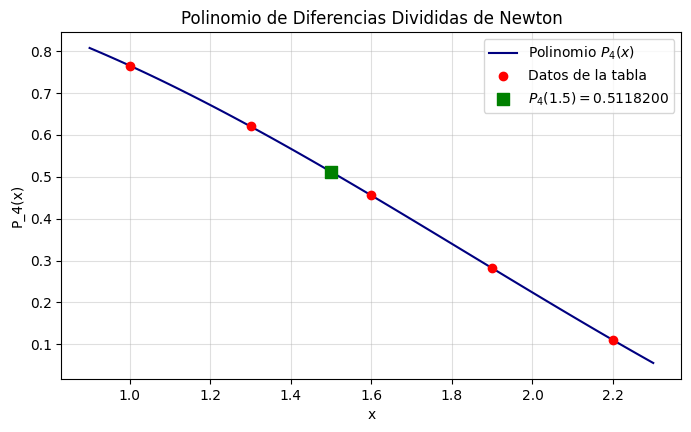

In [10]:
def polinomio_newton(coef, xi, yi, x_eval=1.5):
    xs = sp.Symbol('x')
    n = len(coef) - 1

    P = coef[0]
    termino = 1

    for k in range(1, n + 1):
        termino = termino * (xs - xi[k - 1])
        P = P + coef[k] * termino

    print("Polinomio de Newton P_4(x):")
    display(P)

    print("\nPolinomio desarrollado:")
    display(sp.expand(P))

    # Evaluado en x = 1.5
    res = float(P.subs(xs, x_eval))
    print(f"\nEvaluación en x = {x_eval}:  P_4({x_eval}) = {res:.7f}")

    f_num = sp.lambdify(xs, P, 'numpy') #convertir la expresión de sympy en una función numérica para graficar
    x_graf = np.linspace(0.9, 2.3, 100)
    y_graf = f_num(x_graf)

    plt.figure(figsize=(8, 4.5))
    plt.plot(x_graf, y_graf, label="Polinomio $P_4(x)$", color="navy")
    plt.scatter(xi, yi, color="red", label="Datos de la tabla", zorder=5)
    plt.scatter([x_eval], [res], color="green", marker="s", s=70,
                label=f"$P_4(1.5) = {res:.7f}$", zorder=6)

    plt.title("Polinomio de Diferencias Divididas de Newton")
    plt.xlabel("x")
    plt.ylabel("P_4(x)")
    plt.grid(True, alpha=0.4)
    plt.legend()
    plt.show()

polinomio_newton(a, x, fx, x_eval=1.5)